In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# 03 · Context selection strategies

## tl;dr
Compare random, stratified, class-balanced, diversity, similarity and hybrid selection at a fixed 128-row budget. Validation results, not final-holdout results, choose the final global strategy.

## Methods
Numeric features are standardized and categorical fields one-hot encoded using eligible context data only. Similarity and hybrid each completed the full 128-invoice holdout with one seed after API rate limiting; global strategies have five seeds. Balanced sampling changes the effective class prior, so inspect false positives.

In [2]:
validation = pd.read_csv(ROOT / 'data/context_benchmark/selection_validation_results.csv')
result = pd.read_csv(ROOT / 'data/context_benchmark/selection_holdout_results.csv')
chosen = validation.groupby(['target','strategy']).f1.mean().groupby(level=0).idxmax()
display(pd.DataFrame({'validation_selected_strategy': {k:v[1] for k,v in chosen.items()}}))
display(result.groupby(['target','strategy'])[['f1','recall','false_positives','context_build_seconds','inference_seconds']].agg(['mean','std']).round(3))

,validation_selected_strategy
is_fraud,balanced
paid_late,balanced


f1        recall        false_positives          \
                       mean    std   mean    std            mean     std   
target    strategy                                                         
is_fraud  balanced    0.388  0.018  0.750  0.000            17.0   1.414   
          diversity   0.000  0.000  0.000  0.000             0.2   0.447   
          hybrid      0.000    NaN  0.000    NaN             1.0     NaN   
          random      0.000  0.000  0.000  0.000             0.0   0.000   
          similarity  0.000    NaN  0.000    NaN             1.0     NaN   
          stratified  0.000  0.000  0.000  0.000             0.4   0.894   
paid_late balanced    0.558  0.060  0.616  0.082            30.0   6.285   
          diversity   0.514  0.097  0.529  0.254            23.0  17.649   
          hybrid      0.630    NaN  0.784    NaN            36.0     NaN   
          random      0.544  0.031  0.557  0.093            24.6   6.693   
          similarity  0.579    NaN  0.608    NaN            25.0     NaN   
          stratified  0.494  0.038  0.478  0.088            23.2   9.418   

                     context_build_seconds        inference_seconds         
                                      mean    std              mean    std  
target    strategy                                                          
is_fraud  balanced                   0.001  0.000             0.665  0.597  
          diversity                  0.033  0.005             0.325  0.058  
          hybrid                     3.467    NaN           250.434    NaN  
          random                     0.001  0.000             0.398  0.081  
          similarity                 1.375    NaN           247.111    NaN  
          stratified                 0.001  0.000             0.525  0.228  
paid_late balanced                   0.001  0.000             0.424  0.079  
          diversity                  0.033  0.003             0.368  0.056  
          hybrid                     2.765    NaN           245.476    NaN  
          random                     0.001  0.000             0.395  0.029  
          similarity                 1.448    NaN           253.491    NaN  
          stratified                 0.001  0.000             0.465  0.118

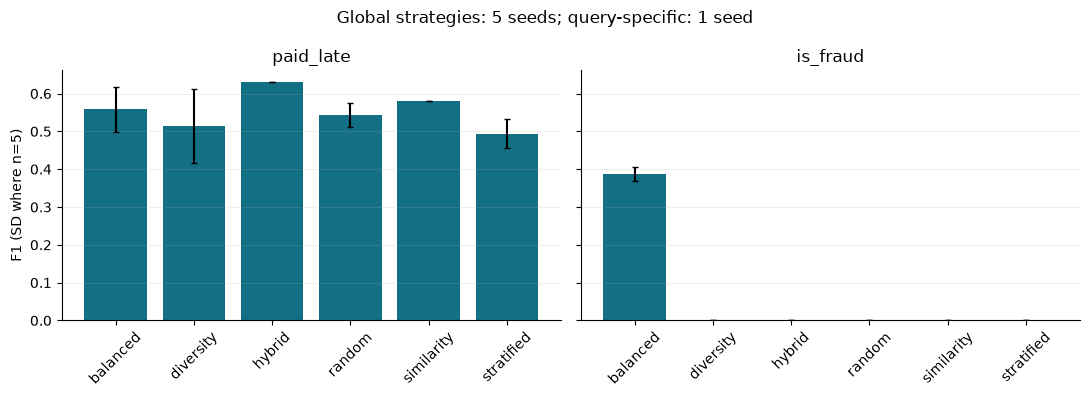

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11,4), sharey=True)
for ax, target in zip(axes,['paid_late','is_fraud']):
    sub=result[result.target==target].groupby('strategy').f1.agg(['mean','std'])
    ax.bar(sub.index,sub['mean'],yerr=sub['std'].fillna(0),capsize=2,color='#136f84'); ax.tick_params(axis='x',rotation=45); ax.set_title(target); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('F1 (SD where n=5)'); fig.suptitle('Global strategies: 5 seeds; query-specific: 1 seed'); plt.tight_layout(); plt.show()

## Takeaways
The final strategy must be named from validation before reading the final holdout. Similarity and hybrid are exploratory one-seed measurements with one SAP request per invoice; neither was eligible for the validation-selected final strategy. Their cumulative runtime includes API pacing and retry delays.